<a href="https://colab.research.google.com/github/fattah-abdullah/ProyekAkhir_5A_CardiovascularDisease/blob/main/P12_Data_Bersama_kelompok6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 12 — Penyiapan Data (Bagian Bersama)
## Proyek Akhir Pembelajaran Mesin (INF62325) — Cabang A: Regresi Linear

| | |
|---|---|
| Kelompok | 6 |
| Dataset | Cardiovascular Disease |

| Anggota | NIM | Varian yang dipegang | Notebook yang dikerjakan |
|---|---|---|---|
| Salwa Ayudia Putri | 2488010042 | **1 — Dasar** | `P12A_Varian1_Dasar.ipynb` |
| Mifa Miftahul Falaah | 2488010072 | **2 — Perlakuan data** | `P12B_Varian2_Perlakuan_Data.ipynb` |
| Abdullah Fattah | 2488010067 | **3 — Pemilihan fitur** | `P12C_Varian3_Pemilihan_Fitur.ipynb` |

---

### Panduan notebook ini

**Notebook ini dikerjakan bersama, satu kali, oleh satu orang sementara dua
lainnya menyaksikan.** Hasilnya dipakai ketiga anggota.

**Mengapa harus bersama.** Perbandingan antarvarian baru sah bila ketiganya
diukur pada data uji yang sama persis. Kalau tiap anggota membagi datanya
sendiri, selisih angka di Pertemuan 13 bisa berasal dari keberuntungan
pembagian, bukan dari perlakuan data — dan kesalahan itu tidak memunculkan
galat apa pun.

**Luaran.** `p12_data.joblib`, berisi data yang sudah dibagi beserta
**sidik jari** pembagiannya. Ketiga notebook varian memeriksa sidik jari itu
dan berhenti bila tidak cocok.

**Setelah notebook ini selesai,** ketiga anggota membuka notebook variannya
masing-masing dan bekerja sendiri-sendiri, boleh bersamaan.

**Perkiraan waktu.** 45 menit.

---
## Langkah A — Samakan versi scikit-learn (WAJIB, setiap kali membuka notebook ini)

Colab memulai sesi baru setiap kali notebook dibuka, jadi langkah ini diulang
**di setiap pertemuan**, bukan sekali saja.

Gunanya menyamakan versi scikit-learn di Colab dengan versi yang dipasang
Streamlit Community Cloud. Tanpa ini, model berhasil dilatih tetapi gagal dimuat
di aplikasi web dengan galat
`AttributeError: ... has no attribute '_RemainderColsList'`.

In [73]:
!pip install -q scikit-learn==1.9.1

### Restart dulu, jangan dilewati

Pilih menu **Runtime → Restart session**, lalu jalankan ulang dari sel paling atas.
Tanpa restart, Python masih memakai scikit-learn versi lama yang sudah terlanjur
dimuat ke memori, dan kesalahannya tidak terlihat sampai tahap paling akhir.

In [74]:
import sklearn

print("scikit-learn:", sklearn.__version__)
assert sklearn.__version__ == "1.9.1", (
    "Versi belum sesuai. Jalankan sel pip di atas, lalu Runtime -> Restart session, "
    "lalu jalankan ulang dari sel paling atas."
)
print("Versi sudah sesuai.")

scikit-learn: 1.9.1
Versi sudah sesuai.


---
## Langkah B — Hubungkan Google Drive

Setiap pertemuan menyimpan hasilnya ke satu folder Drive yang sama, lalu pertemuan
berikutnya membacanya dari sana. Dengan begitu pekerjaan tidak hilang saat sesi Colab
berakhir, dan tidak perlu mengulang dari awal tiap minggu.

Folder yang dipakai: `/content/drive/MyDrive/ProyekAkhirML_RegresiLinear`

Saat sel di bawah dijalankan, Colab meminta izin mengakses Drive. Pilih akun Google
kelompok, lalu setujui.

In [75]:
import os
from google.colab import drive

drive.mount("/content/drive")

FOLDER = "/content/drive/MyDrive/ProyekAkhirML_RegresiLinear"
os.makedirs(FOLDER, exist_ok=True)

print("Folder proyek:", FOLDER)
print("Isi folder   :", sorted(os.listdir(FOLDER)) or "(masih kosong)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder proyek: /content/drive/MyDrive/ProyekAkhirML_RegresiLinear
Isi folder   : ['data_mentah.csv', 'p12_data.joblib']


---
## Langkah C — Mengunduh data dari Kaggle

In [76]:
# !pip install -q kagglehub      # hapus tanda # bila kagglehub belum ada

import kagglehub
import pandas as pd

SLUG = "sulianova/cardiovascular-disease-dataset"     # ganti sesuai paket dataset kelompok
TARGET = "ap_hi"                  # ganti sesuai kolom target kelompok

path = kagglehub.dataset_download(SLUG)
print("Folder unduhan:", path)
print("Isi folder   :", os.listdir(path))

Using Colab cache for faster access to the 'cardiovascular-disease-dataset' dataset.
Folder unduhan: /kaggle/input/cardiovascular-disease-dataset
Isi folder   : ['cardio_train.csv']


In [77]:
NAMA_FILE = "cardio_train.csv"     # sesuaikan dengan hasil os.listdir di atas

df = pd.read_csv(os.path.join(path, NAMA_FILE), sep=";")
df.to_csv(os.path.join(FOLDER, "data_mentah.csv"), index=False)

df_kerja = df.copy()
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


---
## Langkah D — Eksplorasi data

Hasil eksplorasi inilah yang menjadi bekal ketiga anggota: Varian 2 memerlukan
gambaran pencilan, dan Varian 3 memerlukan tabel korelasi. Jalankan bersama,
dan **ketiganya mencatat angkanya masing-masing**.

In [78]:
df_kerja.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [79]:
df_kerja.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [80]:
# Nilai hilang dan baris duplikat
hilang = df_kerja.isna().sum().sort_values(ascending=False)
print((hilang / len(df_kerja) * 100).round(2).to_string())
print("\nBaris duplikat:", df_kerja.duplicated().sum())

# Memeriksa dan memastikan seluruh variabel numerik yang tidak memiliki nilai negatif.
numerik = ['ap_hi', 'ap_lo', 'height', 'weight']
jumlah_sebelum = len(df_kerja)

negative_mask = (
    df_kerja[numerik] < 0
).any(axis=1)

jumlah_negatif = negative_mask.sum()
print("Jumlah baris dengan nilai negatif:", jumlah_negatif)

# Kardinalitas kolom kategorik (yang sudah di-encode di dataset)
objek = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']
print("\nKategori unik per kolom:")
print(df_kerja[objek].nunique().sort_values(ascending=False).to_string())
for kol in objek:
    print(f"\n{kol}: {sorted(df_kerja[kol].unique())}")

id             0.0
age            0.0
gender         0.0
height         0.0
weight         0.0
ap_hi          0.0
ap_lo          0.0
cholesterol    0.0
gluc           0.0
smoke          0.0
alco           0.0
active         0.0
cardio         0.0

Baris duplikat: 0
Jumlah baris dengan nilai negatif: 8

Kategori unik per kolom:
cholesterol    3
gluc           3
gender         2
smoke          2
alco           2
active         2
cardio         2

gender: [np.int64(1), np.int64(2)]

cholesterol: [np.int64(1), np.int64(2), np.int64(3)]

gluc: [np.int64(1), np.int64(2), np.int64(3)]

smoke: [np.int64(0), np.int64(1)]

alco: [np.int64(0), np.int64(1)]

active: [np.int64(0), np.int64(1)]

cardio: [np.int64(0), np.int64(1)]


In [81]:
# Korelasi terhadap target - bekal Varian 3
korelasi = df_kerja.corr(numeric_only=True)[TARGET].sort_values(ascending=False)
print(korelasi.round(4).to_string())
print("\nKemencengan target:", round(float(df_kerja[TARGET].skew()), 4))

ap_hi          1.0000
cardio         0.0545
weight         0.0307
cholesterol    0.0238
age            0.0208
ap_lo          0.0161
gluc           0.0118
gender         0.0060
height         0.0055
id             0.0034
alco           0.0014
active        -0.0000
smoke         -0.0009

Kemencengan target: 85.2962


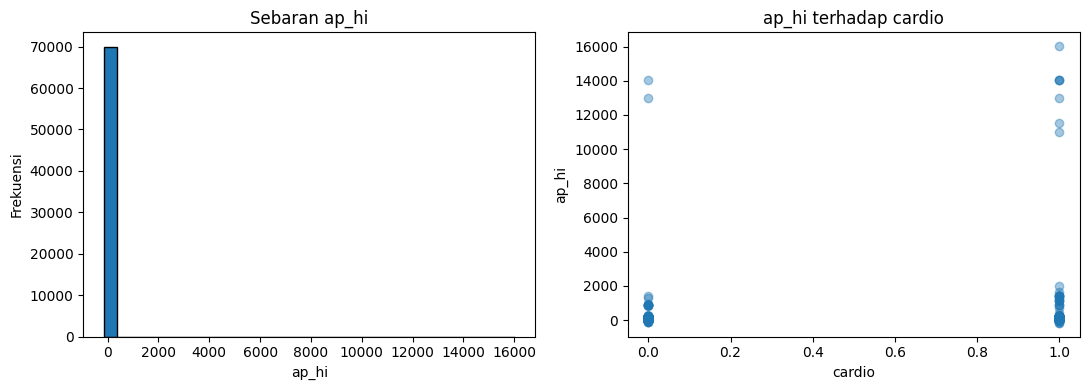

In [82]:
import matplotlib.pyplot as plt

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.hist(df_kerja[TARGET].dropna(), bins=30, edgecolor="black")
a.set_xlabel(TARGET); a.set_ylabel("Frekuensi"); a.set_title(f"Sebaran {TARGET}")

FITUR_KUAT = korelasi.index[1]
b.scatter(df_kerja[FITUR_KUAT], df_kerja[TARGET], alpha=0.4)
b.set_xlabel(FITUR_KUAT); b.set_ylabel(TARGET)
b.set_title(f"{TARGET} terhadap {FITUR_KUAT}")
plt.tight_layout(); plt.show()

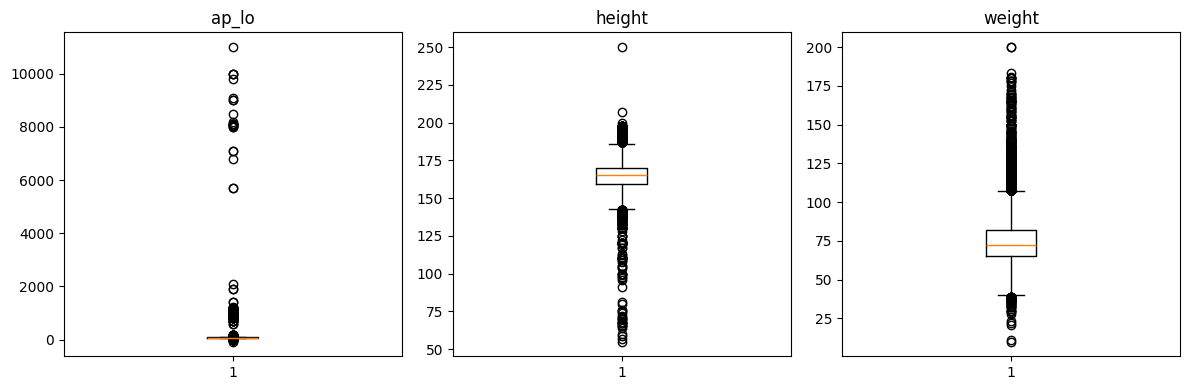

In [85]:
# Boxplot kolom numerik - bekal Varian 2
kolom_angka = df_kerja[numerik].drop(columns=[TARGET]).columns

fig, sumbu = plt.subplots(1, len(kolom_angka), figsize=(4 * len(kolom_angka), 4))
sumbu = [sumbu] if len(kolom_angka) == 1 else sumbu
for ax, kol in zip(sumbu, kolom_angka):
    ax.boxplot(df_kerja[kol].dropna())
    ax.set_title(kol)
plt.tight_layout(); plt.show()

### Keputusan dari eksplorasi — ISI SEL INI

Sebutkan angkanya. Sel ini dinilai, dan isinya dipakai ketiga anggota.

- Nilai hilang: 0
- Baris duplikat: 0
- Baris dengan numerik negatif: 8
- Kardinalitas kategorik: 8, tapi semua kolom itu sudah di encoding dari kaggle/pemilik datasetnya.
- Kolom numerik yang terlihat punya pencilan pada boxplot: 3 -> `weight`, `height` dan `ap_lo`
- Urutan korelasi terhadap target:<br>1. `ap_hi`<br>2. `cardio`<br>3. `weight`<br>4. `cholestrol`<br>5. `age`<br>6. `ap_lo`<br>7. `gluc`<br>8. `gender`<br>9. `height`<br>10. `id`<br>11. `alco`<br>12. `active`<br>13. `smoke`

---
## Langkah E — Pembersihan dan pembagian data

Dijalankan **sekali**, dan tidak boleh diulang di notebook varian mana pun.
`random_state=42` membuat pembagiannya bisa dihasilkan ulang bila berkasnya
hilang; jangan diubah.

In [90]:
from sklearn.model_selection import train_test_split

# Mempersiapkan data bersih
df_bersih = df_kerja.drop_duplicates()
df_bersih = df_bersih.dropna(subset=[TARGET])
df_bersih = df_bersih.drop(columns=['id', 'cardio'])

# Memfilter baris dengan nilai negatif pada kolom numerik
negative_mask_clean = (df_bersih[numerik] < 0).any(axis=1)
df_bersih = df_bersih[~negative_mask_clean]

print("Baris sebelum:", len(df_kerja), "| sesudah:", len(df_bersih))

# Memisahkan fitur dan target
X = df_bersih.drop(columns=[TARGET])
y = df_bersih[TARGET]

# Split data
X_latih, X_uji, y_latih, y_uji = train_test_split(X, y, test_size=0.2, random_state=42)
print("Data latih:", X_latih.shape, "| Data uji:", X_uji.shape)

# Menentukan kolom numerik dan kategorik untuk fitur
kolom_numerik = [col for col in numerik if col in X_latih.columns]
kolom_kategorik = [col for col in objek if col in X_latih.columns]

print("Numerik  :", kolom_numerik)
print("Kategorik:", kolom_kategorik)

Baris sebelum: 70000 | sesudah: 69992
Data latih: (55993, 10) | Data uji: (13999, 10)
Numerik  : ['ap_lo', 'height', 'weight']
Kategorik: ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']


### Sidik jari pembagian data

Sel berikut menghitung satu kode pendek dari daftar baris yang masuk data uji.
Ketiga notebook varian menghitung ulang kode itu dan membandingkannya dengan
yang tersimpan di sini.

Gunanya satu: kalau ada anggota yang menjalankan `train_test_split` sendiri di
notebooknya, kodenya berbeda dan notebook itu berhenti dengan pesan yang jelas —
sebelum angkanya terlanjur masuk ke tabel perbandingan.

In [93]:
import hashlib

def sidik_jari(X_uji):
    """Sidik jari pembagian data uji.

    Dipakai ketiga notebook varian untuk membuktikan bahwa mereka benar-benar
    memakai data uji yang sama. Bila ada anggota yang menjalankan
    train_test_split sendiri, sidik jarinya berbeda dan notebook berhenti.
    """
    isi = "|".join(str(i) for i in sorted(X_uji.index.tolist()))
    isi += f"|{X_uji.shape[0]}x{X_uji.shape[1]}"
    return hashlib.sha256(isi.encode()).hexdigest()[:16]


SIDIK = sidik_jari(X_uji)
print("Sidik jari data uji:", SIDIK)
print("\nCatat kode ini. Ketiga notebook varian harus mencetak kode yang sama.")

Sidik jari data uji: 3e147073c4769645

Catat kode ini. Ketiga notebook varian harus mencetak kode yang sama.


---
## Langkah F — Menyimpan hasil ke Drive

In [94]:
import joblib

hasil_p12 = {
    "X_latih": X_latih, "X_uji": X_uji,
    "y_latih": y_latih, "y_uji": y_uji,
    "kolom_numerik": kolom_numerik,
    "kolom_kategorik": kolom_kategorik,
    "TARGET": TARGET,
    "sidik_jari_uji": SIDIK,
    "sumber_dataset": f"https://www.kaggle.com/datasets/{SLUG}",
}

joblib.dump(hasil_p12, os.path.join(FOLDER, "p12_data.joblib"))
print("Tersimpan: p12_data.joblib")
print("Isi folder:", sorted(os.listdir(FOLDER)))

Tersimpan: p12_data.joblib
Isi folder: ['data_mentah.csv', 'p12_data.joblib']


---
## Isi folder Drive setelah notebook ini

```
ProyekML_RegresiLinear/          ← folder Google Drive kelompok
├── data_mentah.csv              ← DIHASILKAN HARI INI
└── p12_data.joblib              ← DIHASILKAN HARI INI
```

## Daftar periksa

- [X] Tabel pembagian varian terisi nama, NIM, dan notebook masing-masing
- [X] Sel keputusan eksplorasi terisi dengan angka
- [X] `train_test_split` dijalankan **sekali**, hanya di notebook ini
- [X] Sidik jari data uji sudah dicetak dan dicatat ketiga anggota
- [X] Sel Langkah F mencetak `Tersimpan: p12_data.joblib`
- [X] Folder Drive sudah dibagikan ke kedua anggota lain dengan akses **Editor**

## Langkah berikutnya

Ketiga anggota membuka notebook variannya sendiri. Boleh dikerjakan bersamaan
di tiga komputer, karena masing-masing menulis berkas dengan nama berbeda ke
folder Drive yang sama.

| Anggota | Notebook | Menghasilkan |
|---|---|---|
| Varian 1 | `P12A_Varian1_Dasar.ipynb` | `varian1.joblib`, `varian1_hasil.json` |
| Varian 2 | `P12B_Varian2_Perlakuan_Data.ipynb` | `varian2.joblib`, `varian2_hasil.json` |
| Varian 3 | `P12C_Varian3_Pemilihan_Fitur.ipynb` | `varian3.joblib`, `varian3_hasil.json` |

Notebook Pertemuan 13 tidak bisa dijalankan sebelum **ketiganya** selesai.